<a href="https://colab.research.google.com/github/samar8x/CVIP_Project/blob/main/Notebooks/11_Paired_Bootstrap_Model_Improvement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 11 — Paired Bootstrap of Model Improvement

## Goal

Quantify how stable the **Modified − Original** improvement is on the untouched ACDC validation set.

Notebook 10 already evaluated both models on the **same 406 ACDC validation images** and saved one paired confusion-matrix file per image.

for each adverse condition:
1. Resample validation images **with replacement**.
2. Use the same sampled image indices for the original and modified models.
3. Sum the corresponding confusion matrices.
4. Recompute mIoU and per-class IoU.
5. Store **Modified − Original**.
6. Repeat 1,000 times.
7. Report the 95% percentile interval and the fraction of bootstrap resamples with improvement > 0.

This answers:

> Are the observed before/after gains stable across resampled validation images?


In [ ]:
# Mount Google Drive FIRST before checking any project paths
from pathlib import Path
from google.colab import drive

MYDRIVE = Path('/content/drive/MyDrive')

if MYDRIVE.exists():
    print('✓ Google Drive is already mounted.')
else:
    drive.mount('/content/drive')

assert MYDRIVE.exists(), 'Google Drive mount failed: /content/drive/MyDrive is not available.'
print('✓ Google Drive ready:', MYDRIVE)


Mounted at /content/drive
✓ Google Drive ready: /content/drive/MyDrive


In [ ]:

import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 100)


In [ ]:
from pathlib import Path

p = Path(
    '/content/drive/MyDrive/CV_Project/results/'
    'model_modification/validation_evaluation/per_image_confusions_v1'
)

print("Exists:", p.exists())

if p.exists():
    print("NPZ files:", len(list(p.glob("*.npz"))))

Exists: True
NPZ files: 406


In [ ]:
# Project paths
PROJECT_ROOT = Path('/content/drive/MyDrive/CV_Project')
RESULTS_DIR = PROJECT_ROOT / 'results'

MODEL_MOD_DIR = RESULTS_DIR / 'model_modification'

# Notebook 10 results are inside model_modification
EVAL_RESULTS_DIR = MODEL_MOD_DIR / 'validation_evaluation'
PER_IMAGE_CACHE_DIR = EVAL_RESULTS_DIR / 'per_image_confusions_v1'

# Notebook 11 results
BOOT_DIR = MODEL_MOD_DIR / 'bootstrap_improvement'
BOOT_DIR.mkdir(parents=True, exist_ok=True)

CONDITIONS = ['fog', 'rain', 'snow', 'night']
NUM_CLASSES = 19

CLASS_NAMES = [
    'road', 'sidewalk', 'building', 'wall', 'fence', 'pole',
    'traffic light', 'traffic sign', 'vegetation', 'terrain', 'sky',
    'person', 'rider', 'car', 'truck', 'bus', 'train',
    'motorcycle', 'bicycle'
]

GROUPS = {
    'Static Thin': ['pole', 'traffic light', 'traffic sign'],
    'Dynamic Small': ['person', 'rider', 'motorcycle', 'bicycle'],
    'Large/Structural': ['road', 'building', 'vegetation', 'terrain', 'sky'],
}

CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}

assert PER_IMAGE_CACHE_DIR.exists(), (
    f"Missing cache folder: {PER_IMAGE_CACHE_DIR}"
)

cache_files = list(PER_IMAGE_CACHE_DIR.glob('*.npz'))

print("Using paired cache:", PER_IMAGE_CACHE_DIR)
print("Cache files found:", len(cache_files))
print("Bootstrap output:", BOOT_DIR)

assert len(cache_files) == 406, (
    f"Expected 406 paired cache files, found {len(cache_files)}"
)

print("✓ Correct validation cache path verified.")

Using paired cache: /content/drive/MyDrive/CV_Project/results/model_modification/validation_evaluation/per_image_confusions_v1
Cache files found: 406
Bootstrap output: /content/drive/MyDrive/CV_Project/results/model_modification/bootstrap_improvement
✓ Correct validation cache path verified.



## 1. Load the 406 paired per-image confusion matrices


In [ ]:

cache_files = sorted(PER_IMAGE_CACHE_DIR.glob('*.npz'))
print("Cache files found:", len(cache_files))
assert len(cache_files) == 406, f"Expected 406 paired files, found {len(cache_files)}"

records = []

for f in cache_files:
    d = np.load(f, allow_pickle=True)

    condition = str(d['condition'].item())
    scene_key = str(d['scene_key'].item())
    baseline_cm = d['baseline_confusion'].astype(np.int64)
    modified_cm = d['modified_confusion'].astype(np.int64)

    assert baseline_cm.shape == (NUM_CLASSES, NUM_CLASSES)
    assert modified_cm.shape == (NUM_CLASSES, NUM_CLASSES)

    records.append({
        'condition': condition,
        'scene_key': scene_key,
        'baseline_cm': baseline_cm,
        'modified_cm': modified_cm,
        'valid_pixels': int(d['valid_pixels'].item()),
        'total_pixels': int(d['total_pixels'].item()),
    })

records_df = pd.DataFrame(records)

counts = records_df.groupby('condition').size().reindex(CONDITIONS)
display(counts.rename('images').to_frame())

assert counts.to_dict() == {'fog': 100, 'rain': 100, 'snow': 100, 'night': 106}
print("✓ Paired validation caches verified.")


Cache files found: 406


,images
condition,
fog,100
rain,100
snow,100
night,106


✓ Paired validation caches verified.



## 2. Metric helpers


In [ ]:

def iou_from_confusion(cm):
    cm = np.asarray(cm, dtype=np.float64)
    tp = np.diag(cm)
    gt = cm.sum(axis=1)
    pred = cm.sum(axis=0)
    union = gt + pred - tp

    iou = np.full(NUM_CLASSES, np.nan, dtype=np.float64)
    valid = union > 0
    iou[valid] = tp[valid] / union[valid]
    return iou


def miou_from_confusion(cm):
    return float(np.nanmean(iou_from_confusion(cm)))


def group_mean_from_iou(iou_vec, members):
    vals = []
    for name in members:
        v = iou_vec[CLASS_TO_ID[name]]
        if np.isfinite(v):
            vals.append(v)
    return float(np.mean(vals)) if vals else np.nan



## 3. Recompute original-sample point estimates from the caches



In [ ]:

point_rows = []
point_class_rows = []
point_group_rows = []

condition_arrays = {}

for condition in CONDITIONS:
    sub = records_df[records_df['condition'] == condition].reset_index(drop=True)

    baseline_stack = np.stack(sub['baseline_cm'].to_list(), axis=0)
    modified_stack = np.stack(sub['modified_cm'].to_list(), axis=0)

    condition_arrays[condition] = {
        'baseline': baseline_stack,
        'modified': modified_stack,
        'scene_keys': sub['scene_key'].tolist(),
    }

    b_sum = baseline_stack.sum(axis=0)
    m_sum = modified_stack.sum(axis=0)

    b_iou = iou_from_confusion(b_sum)
    m_iou = iou_from_confusion(m_sum)

    b_miou = float(np.nanmean(b_iou))
    m_miou = float(np.nanmean(m_iou))

    point_rows.append({
        'condition': condition,
        'images': len(sub),
        'baseline_mIoU': b_miou,
        'modified_mIoU': m_miou,
        'mIoU_improvement': m_miou - b_miou,
    })

    for cid, cname in enumerate(CLASS_NAMES):
        point_class_rows.append({
            'condition': condition,
            'class_id': cid,
            'class_name': cname,
            'baseline_IoU': b_iou[cid],
            'modified_IoU': m_iou[cid],
            'IoU_improvement': (
                m_iou[cid] - b_iou[cid]
                if np.isfinite(b_iou[cid]) and np.isfinite(m_iou[cid])
                else np.nan
            ),
        })

    for gname, members in GROUPS.items():
        b_g = group_mean_from_iou(b_iou, members)
        m_g = group_mean_from_iou(m_iou, members)
        point_group_rows.append({
            'condition': condition,
            'group': gname,
            'baseline_group_IoU': b_g,
            'modified_group_IoU': m_g,
            'group_IoU_improvement': (
                m_g - b_g if np.isfinite(b_g) and np.isfinite(m_g) else np.nan
            ),
        })

point_df = pd.DataFrame(point_rows)
point_class_df = pd.DataFrame(point_class_rows)
point_group_df = pd.DataFrame(point_group_rows)

display(point_df.style.format({
    'baseline_mIoU': '{:.4f}',
    'modified_mIoU': '{:.4f}',
    'mIoU_improvement': '{:+.4f}',
}))


,condition,images,baseline_mIoU,modified_mIoU,mIoU_improvement
0,fog,100,0.6968,0.7309,+0.0341
1,rain,100,0.5001,0.6182,+0.1181
2,snow,100,0.4875,0.6645,+0.1770
3,night,106,0.3294,0.4300,+0.1006



## 4. Paired bootstrap

Important:

- Resampling is done **within each condition**.
- The same sampled image indices are applied to the original and modified confusion matrices.
- We bootstrap **images**, not pixels.
- 1,000 resamples are used.
- The reported intervals are descriptive 95% percentile intervals.


In [ ]:

N_BOOT = 1000
SEEDS = {
    'fog': 142,
    'rain': 143,
    'snow': 144,
    'night': 145,
}

bootstrap_store = {}

for condition in CONDITIONS:
    baseline_stack = condition_arrays[condition]['baseline']
    modified_stack = condition_arrays[condition]['modified']

    n = baseline_stack.shape[0]
    rng = np.random.default_rng(SEEDS[condition])

    miou_improvements = np.full(N_BOOT, np.nan, dtype=np.float64)
    class_improvements = np.full((N_BOOT, NUM_CLASSES), np.nan, dtype=np.float64)
    group_improvements = {
        g: np.full(N_BOOT, np.nan, dtype=np.float64)
        for g in GROUPS
    }

    for b in tqdm(range(N_BOOT), desc=f'Bootstrap {condition}'):
        idx = rng.integers(0, n, size=n)

        b_cm = baseline_stack[idx].sum(axis=0)
        m_cm = modified_stack[idx].sum(axis=0)

        b_iou = iou_from_confusion(b_cm)
        m_iou = iou_from_confusion(m_cm)

        miou_improvements[b] = float(np.nanmean(m_iou) - np.nanmean(b_iou))

        finite = np.isfinite(b_iou) & np.isfinite(m_iou)
        class_improvements[b, finite] = m_iou[finite] - b_iou[finite]

        for gname, members in GROUPS.items():
            b_g = group_mean_from_iou(b_iou, members)
            m_g = group_mean_from_iou(m_iou, members)

            if np.isfinite(b_g) and np.isfinite(m_g):
                group_improvements[gname][b] = m_g - b_g

    bootstrap_store[condition] = {
        'miou': miou_improvements,
        'class': class_improvements,
        'group': group_improvements,
    }

print("✓ Paired bootstrap complete.")


Bootstrap fog:   0%|          | 0/1000 [00:00<?, ?it/s]

Bootstrap rain:   0%|          | 0/1000 [00:00<?, ?it/s]

Bootstrap snow:   0%|          | 0/1000 [00:00<?, ?it/s]

Bootstrap night:   0%|          | 0/1000 [00:00<?, ?it/s]

✓ Paired bootstrap complete.



## 5. Bootstrap summary helper


In [ ]:

def summarize_bootstrap(values):
    values = np.asarray(values, dtype=np.float64)
    finite = values[np.isfinite(values)]

    if len(finite) == 0:
        return {
            'bootstrap_mean': np.nan,
            'ci_low': np.nan,
            'ci_high': np.nan,
            'positive_fraction': np.nan,
            'negative_fraction': np.nan,
            'finite_resamples': 0,
        }

    return {
        'bootstrap_mean': float(np.mean(finite)),
        'ci_low': float(np.percentile(finite, 2.5)),
        'ci_high': float(np.percentile(finite, 97.5)),
        'positive_fraction': float(np.mean(finite > 0)),
        'negative_fraction': float(np.mean(finite < 0)),
        'finite_resamples': int(len(finite)),
    }



## 6. Condition-level mIoU improvement uncertainty


In [ ]:

miou_boot_rows = []

for condition in CONDITIONS:
    point = point_df.loc[
        point_df['condition'] == condition, 'mIoU_improvement'
    ].iloc[0]

    s = summarize_bootstrap(bootstrap_store[condition]['miou'])

    miou_boot_rows.append({
        'condition': condition,
        'original_sample_improvement': point,
        **s,
    })

miou_boot_df = pd.DataFrame(miou_boot_rows)
miou_boot_df.to_csv(
    BOOT_DIR / 'miou_improvement_bootstrap_summary.csv',
    index=False
)

display(
    miou_boot_df.style.format({
        'original_sample_improvement': '{:+.4f}',
        'bootstrap_mean': '{:+.4f}',
        'ci_low': '{:+.4f}',
        'ci_high': '{:+.4f}',
        'positive_fraction': '{:.1%}',
        'negative_fraction': '{:.1%}',
    })
)


,condition,original_sample_improvement,bootstrap_mean,ci_low,ci_high,positive_fraction,negative_fraction,finite_resamples
0,fog,+0.0341,+0.0369,+0.0179,+0.0581,99.9%,0.1%,1000
1,rain,+0.1181,+0.1110,+0.0653,+0.1448,100.0%,0.0%,1000
2,snow,+0.1770,+0.1701,+0.1233,+0.2125,100.0%,0.0%,1000
3,night,+0.1006,+0.1002,+0.0784,+0.1239,100.0%,0.0%,1000



### Interpretation rule

For this before/after analysis:

- **Interval fully above 0** → the modified model's gain is directionally stable under image-level paired resampling.
- **Interval crosses 0** → the direction is uncertain under resampling.
- **Interval fully below 0** → the modified model is stably worse under this resampling scheme.

These are descriptive bootstrap intervals



## 7. Per-class improvement uncertainty


In [ ]:

class_boot_rows = []

for condition in CONDITIONS:
    arr = bootstrap_store[condition]['class']

    for cid, cname in enumerate(CLASS_NAMES):
        point = point_class_df.loc[
            (point_class_df['condition'] == condition)
            & (point_class_df['class_id'] == cid),
            'IoU_improvement'
        ].iloc[0]

        s = summarize_bootstrap(arr[:, cid])

        class_boot_rows.append({
            'condition': condition,
            'class_id': cid,
            'class_name': cname,
            'original_sample_improvement': point,
            **s,
        })

class_boot_df = pd.DataFrame(class_boot_rows)
class_boot_df.to_csv(
    BOOT_DIR / 'per_class_improvement_bootstrap_summary.csv',
    index=False
)

display(
    class_boot_df.sort_values(
        ['condition', 'original_sample_improvement'],
        ascending=[True, False]
    ).style.format({
        'original_sample_improvement': '{:+.4f}',
        'bootstrap_mean': '{:+.4f}',
        'ci_low': '{:+.4f}',
        'ci_high': '{:+.4f}',
        'positive_fraction': '{:.1%}',
        'negative_fraction': '{:.1%}',
    })
)


,condition,class_id,class_name,original_sample_improvement,bootstrap_mean,ci_low,ci_high,positive_fraction,negative_fraction,finite_resamples
3,fog,3,wall,+0.1361,+0.1282,+0.0449,+0.2357,100.0%,0.0%,1000
14,fog,14,truck,+0.1222,+0.1197,-0.0672,+0.3888,73.0%,27.0%,1000
1,fog,1,sidewalk,+0.1084,+0.1086,+0.0700,+0.1526,100.0%,0.0%,1000
9,fog,9,terrain,+0.0819,+0.0812,+0.0360,+0.1250,100.0%,0.0%,1000
11,fog,11,person,+0.0774,+0.0758,+0.0209,+0.1280,99.7%,0.3%,1000
2,fog,2,building,+0.0659,+0.0658,+0.0470,+0.0894,100.0%,0.0%,1000
5,fog,5,pole,+0.0608,+0.0603,+0.0330,+0.0907,100.0%,0.0%,1000
8,fog,8,vegetation,+0.0349,+0.0349,+0.0277,+0.0430,100.0%,0.0%,1000
0,fog,0,road,+0.0325,+0.0324,+0.0204,+0.0473,100.0%,0.0%,1000
18,fog,18,bicycle,+0.0253,+0.0231,-0.0952,+0.1606,62.7%,37.1%,1000


In [ ]:

# Stable improvements: 95% interval entirely above zero
stable_improvements = class_boot_df[
    class_boot_df['ci_low'] > 0
].copy()

# Stable regressions: 95% interval entirely below zero
stable_regressions = class_boot_df[
    class_boot_df['ci_high'] < 0
].copy()

print("Stable class-condition improvements:", len(stable_improvements))
display(
    stable_improvements
    .sort_values('bootstrap_mean', ascending=False)
    [['condition','class_name','original_sample_improvement',
      'bootstrap_mean','ci_low','ci_high','positive_fraction']]
    .style.format({
        'original_sample_improvement': '{:+.4f}',
        'bootstrap_mean': '{:+.4f}',
        'ci_low': '{:+.4f}',
        'ci_high': '{:+.4f}',
        'positive_fraction': '{:.1%}',
    })
)

print("\nStable class-condition regressions:", len(stable_regressions))
display(
    stable_regressions
    .sort_values('bootstrap_mean')
    [['condition','class_name','original_sample_improvement',
      'bootstrap_mean','ci_low','ci_high','positive_fraction']]
    .style.format({
        'original_sample_improvement': '{:+.4f}',
        'bootstrap_mean': '{:+.4f}',
        'ci_low': '{:+.4f}',
        'ci_high': '{:+.4f}',
        'positive_fraction': '{:.1%}',
    })
)


Stable class-condition improvements: 47


,condition,class_name,original_sample_improvement,bootstrap_mean,ci_low,ci_high,positive_fraction
58,night,sidewalk,+0.5089,+0.5092,+0.4475,+0.5682,100.0%
39,snow,sidewalk,+0.4520,+0.4529,+0.3929,+0.5200,100.0%
34,rain,bus,+0.4187,+0.3880,+0.0149,+0.6465,98.7%
47,snow,terrain,+0.3890,+0.3876,+0.3058,+0.4732,100.0%
20,rain,sidewalk,+0.3835,+0.3834,+0.3185,+0.4422,100.0%
41,snow,wall,+0.3721,+0.3674,+0.2682,+0.4635,100.0%
73,night,train,+0.3071,+0.2965,+0.0860,+0.5821,99.8%
54,snow,train,+0.2564,+0.2640,+0.0298,+0.5168,99.3%
60,night,wall,+0.1682,+0.1652,+0.0909,+0.2498,100.0%
38,snow,road,+0.1588,+0.1586,+0.1358,+0.1825,100.0%



Stable class-condition regressions: 1


,condition,class_name,original_sample_improvement,bootstrap_mean,ci_low,ci_high,positive_fraction
66,night,terrain,-0.1079,-0.1077,-0.1561,-0.0610,0.0%



## 8. Class-group improvement uncertainty


In [ ]:

group_boot_rows = []

for condition in CONDITIONS:
    for gname in GROUPS:
        point = point_group_df.loc[
            (point_group_df['condition'] == condition)
            & (point_group_df['group'] == gname),
            'group_IoU_improvement'
        ].iloc[0]

        s = summarize_bootstrap(
            bootstrap_store[condition]['group'][gname]
        )

        group_boot_rows.append({
            'condition': condition,
            'group': gname,
            'original_sample_improvement': point,
            **s,
        })

group_boot_df = pd.DataFrame(group_boot_rows)
group_boot_df.to_csv(
    BOOT_DIR / 'class_group_improvement_bootstrap_summary.csv',
    index=False
)

display(
    group_boot_df.style.format({
        'original_sample_improvement': '{:+.4f}',
        'bootstrap_mean': '{:+.4f}',
        'ci_low': '{:+.4f}',
        'ci_high': '{:+.4f}',
        'positive_fraction': '{:.1%}',
        'negative_fraction': '{:.1%}',
    })
)


,condition,group,original_sample_improvement,bootstrap_mean,ci_low,ci_high,positive_fraction,negative_fraction,finite_resamples
0,fog,Static Thin,+0.0237,+0.0242,+0.0061,+0.0430,99.8%,0.2%,1000
1,fog,Dynamic Small,-0.0054,+0.0045,-0.0433,+0.0543,54.8%,45.2%,1000
2,fog,Large/Structural,+0.0459,+0.0458,+0.0355,+0.0565,100.0%,0.0%,1000
3,rain,Static Thin,+0.0483,+0.0480,+0.0282,+0.0703,100.0%,0.0%,1000
4,rain,Dynamic Small,+0.0317,+0.0329,-0.0099,+0.0830,93.4%,6.6%,1000
5,rain,Large/Structural,+0.0657,+0.0656,+0.0540,+0.0783,100.0%,0.0%,1000
6,snow,Static Thin,+0.0705,+0.0698,+0.0418,+0.1048,100.0%,0.0%,1000
7,snow,Dynamic Small,+0.0927,+0.0848,+0.0035,+0.2034,98.2%,1.8%,1000
8,snow,Large/Structural,+0.1456,+0.1452,+0.1250,+0.1681,100.0%,0.0%,1000
9,night,Static Thin,+0.1212,+0.1225,+0.0773,+0.1711,100.0%,0.0%,1000



## 9. Plot condition-level paired bootstrap intervals


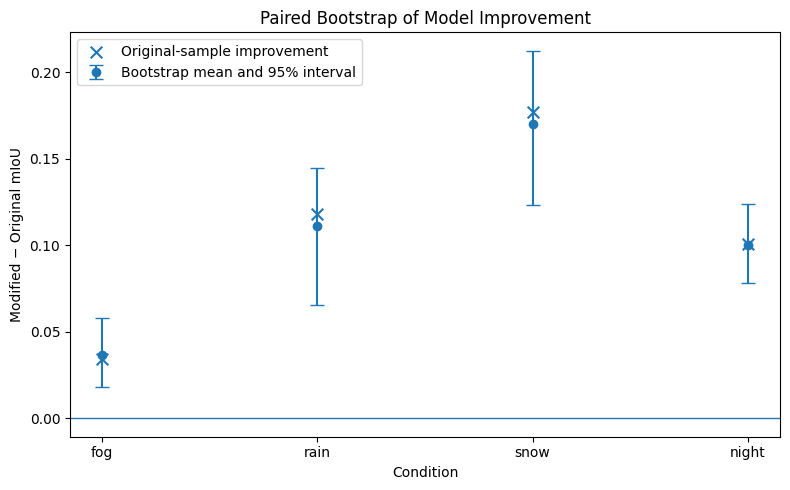

In [ ]:

plot_df = miou_boot_df.copy()

x = np.arange(len(plot_df))
means = plot_df['bootstrap_mean'].values
low = plot_df['ci_low'].values
high = plot_df['ci_high'].values

yerr = np.vstack([means - low, high - means])

plt.figure(figsize=(8,5))
plt.errorbar(
    x,
    means,
    yerr=yerr,
    fmt='o',
    capsize=5,
    label='Bootstrap mean and 95% interval'
)
plt.scatter(
    x,
    plot_df['original_sample_improvement'].values,
    marker='x',
    s=70,
    label='Original-sample improvement'
)

plt.axhline(0, linewidth=1)
plt.xticks(x, plot_df['condition'])
plt.ylabel('Modified − Original mIoU')
plt.xlabel('Condition')
plt.title('Paired Bootstrap of Model Improvement')
plt.legend()
plt.tight_layout()

plt.savefig(
    BOOT_DIR / 'miou_improvement_bootstrap_intervals.png',
    dpi=250,
    bbox_inches='tight'
)
plt.show()



## 10. Per-class stability heatmap

This heatmap shows the **bootstrap mean improvement** for all 19 classes × 4 conditions.

Cells marked with `*` have a 95% interval entirely above zero.

Cells marked with `!` have a 95% interval entirely below zero.


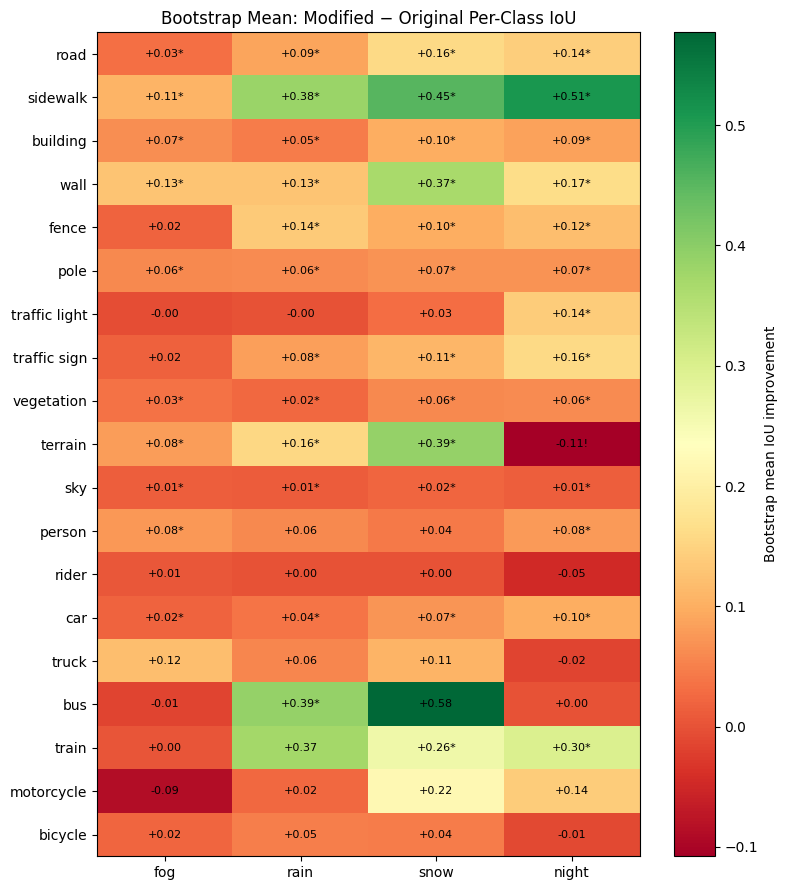

In [ ]:

mean_pivot = class_boot_df.pivot(
    index='class_name',
    columns='condition',
    values='bootstrap_mean'
).reindex(index=CLASS_NAMES, columns=CONDITIONS)

ci_low_pivot = class_boot_df.pivot(
    index='class_name',
    columns='condition',
    values='ci_low'
).reindex(index=CLASS_NAMES, columns=CONDITIONS)

ci_high_pivot = class_boot_df.pivot(
    index='class_name',
    columns='condition',
    values='ci_high'
).reindex(index=CLASS_NAMES, columns=CONDITIONS)

fig, ax = plt.subplots(figsize=(8, 9))

data = mean_pivot.values
im = ax.imshow(data, aspect='auto', cmap='RdYlGn')

ax.set_xticks(range(len(CONDITIONS)), CONDITIONS)
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
ax.set_title('Bootstrap Mean: Modified − Original Per-Class IoU')

for i in range(len(CLASS_NAMES)):
    for j in range(len(CONDITIONS)):
        v = data[i, j]
        lo = ci_low_pivot.values[i, j]
        hi = ci_high_pivot.values[i, j]

        if not np.isfinite(v):
            continue

        marker = ''
        if np.isfinite(lo) and lo > 0:
            marker = '*'
        elif np.isfinite(hi) and hi < 0:
            marker = '!'

        ax.text(
            j, i, f'{v:+.2f}{marker}',
            ha='center', va='center', fontsize=8
        )

fig.colorbar(im, ax=ax, label='Bootstrap mean IoU improvement')
plt.tight_layout()

plt.savefig(
    BOOT_DIR / 'per_class_improvement_bootstrap_heatmap.png',
    dpi=250,
    bbox_inches='tight'
)
plt.show()



## 11. Join with Notebook 09's diagnosis-driven weights

This answers a key project question:

> Did the condition/class combinations deliberately emphasized during modified-model training show stable validation gains?


In [ ]:

WEIGHTS_CSV = PROJECT_ROOT / 'models' / 'vulnerability_aware_segformer_b2' / 'vulnerability_aware_loss_weights.csv'
assert WEIGHTS_CSV.exists(), f"Missing: {WEIGHTS_CSV}"

weight_df = pd.read_csv(WEIGHTS_CSV)

diagnosis_vs_boot = class_boot_df.merge(
    weight_df[
        ['condition','class_id','class_name','matched_change',
         'positive_resample_fraction','pairs_with_class_both',
         'raw_vulnerability_score','loss_weight']
    ],
    on=['condition','class_id','class_name'],
    how='left'
)

diagnosis_vs_boot['was_emphasized'] = diagnosis_vs_boot['loss_weight'] > 1.05
diagnosis_vs_boot['stable_improvement'] = diagnosis_vs_boot['ci_low'] > 0
diagnosis_vs_boot['stable_regression'] = diagnosis_vs_boot['ci_high'] < 0

diagnosis_vs_boot.to_csv(
    BOOT_DIR / 'diagnosis_targets_vs_bootstrap_improvement.csv',
    index=False
)

emph = diagnosis_vs_boot[
    diagnosis_vs_boot['was_emphasized']
    & diagnosis_vs_boot['bootstrap_mean'].notna()
].copy()

print("Diagnosis-emphasized class-condition entries:", len(emph))
print("Mean bootstrap improvement:",
      f"{emph['bootstrap_mean'].mean():+.4f}")
print("Fraction with positive bootstrap mean:",
      f"{(emph['bootstrap_mean'] > 0).mean():.1%}")
print("Fraction with 95% interval fully above zero:",
      f"{emph['stable_improvement'].mean():.1%}")

display(
    emph.sort_values('loss_weight', ascending=False)
    [['condition','class_name','loss_weight',
      'matched_change','positive_resample_fraction',
      'pairs_with_class_both',
      'original_sample_improvement',
      'bootstrap_mean','ci_low','ci_high',
      'stable_improvement']]
    .style.format({
        'loss_weight': '{:.3f}',
        'matched_change': '{:+.4f}',
        'positive_resample_fraction': '{:.1%}',
        'original_sample_improvement': '{:+.4f}',
        'bootstrap_mean': '{:+.4f}',
        'ci_low': '{:+.4f}',
        'ci_high': '{:+.4f}',
    })
)


Diagnosis-emphasized class-condition entries: 35
Mean bootstrap improvement: +0.1303
Fraction with positive bootstrap mean: 82.9%
Fraction with 95% interval fully above zero: 60.0%


,condition,class_name,loss_weight,matched_change,positive_resample_fraction,pairs_with_class_both,original_sample_improvement,bootstrap_mean,ci_low,ci_high,stable_improvement
67,night,sky,2.500,+0.9522,100.0%,154,+0.0122,+0.0128,+0.0040,+0.0260,True
47,snow,terrain,1.826,+0.5246,100.0%,84,+0.3890,+0.3876,+0.3058,+0.4732,True
20,rain,sidewalk,1.550,+0.3494,100.0%,188,+0.3835,+0.3834,+0.3185,+0.4422,True
66,night,terrain,1.358,+0.2274,100.0%,63,-0.1079,-0.1077,-0.1561,-0.0610,False
73,night,train,1.342,+0.3806,94.6%,16,+0.3071,+0.2965,+0.0860,+0.5821,True
56,snow,bicycle,1.337,+0.3367,99.6%,16,+0.0594,+0.0448,-0.0146,+0.1429,False
69,night,rider,1.328,+0.2314,95.0%,27,-0.0500,-0.0476,-0.1364,+0.0000,False
39,snow,sidewalk,1.315,+0.1997,100.0%,193,+0.4520,+0.4529,+0.3929,+0.5200,True
60,night,wall,1.312,+0.1983,100.0%,122,+0.1682,+0.1652,+0.0909,+0.2498,True
65,night,vegetation,1.304,+0.1928,100.0%,193,+0.0628,+0.0630,+0.0420,+0.0847,True



## 12. Automatic project summary


In [ ]:

print("=== MODEL-IMPROVEMENT BOOTSTRAP SUMMARY ===")

for row in miou_boot_df.itertuples(index=False):
    direction = (
        "stable positive gain"
        if row.ci_low > 0
        else "stable regression"
        if row.ci_high < 0
        else "direction uncertain"
    )

    print(
        f"{row.condition.capitalize():>5}: "
        f"point={row.original_sample_improvement:+.4f}, "
        f"bootstrap mean={row.bootstrap_mean:+.4f}, "
        f"95% CI=[{row.ci_low:+.4f}, {row.ci_high:+.4f}], "
        f"positive={row.positive_fraction:.1%} → {direction}"
    )

print()
print("Stable class-condition improvements:", len(stable_improvements))
print("Stable class-condition regressions:", len(stable_regressions))

if len(emph):
    print(
        "Among diagnosis-emphasized entries, "
        f"{emph['stable_improvement'].mean():.1%} have a 95% interval "
        "fully above zero."
    )

print()
print("Interpretation:")
print(
    "These intervals quantify stability under paired resampling of ACDC validation images. "
    "They are descriptive bootstrap intervals and are not adjusted for the many "
    "class-condition comparisons."
)


=== MODEL-IMPROVEMENT BOOTSTRAP SUMMARY ===
  Fog: point=+0.0341, bootstrap mean=+0.0369, 95% CI=[+0.0179, +0.0581], positive=99.9% → stable positive gain
 Rain: point=+0.1181, bootstrap mean=+0.1110, 95% CI=[+0.0653, +0.1448], positive=100.0% → stable positive gain
 Snow: point=+0.1770, bootstrap mean=+0.1701, 95% CI=[+0.1233, +0.2125], positive=100.0% → stable positive gain
Night: point=+0.1006, bootstrap mean=+0.1002, 95% CI=[+0.0784, +0.1239], positive=100.0% → stable positive gain

Stable class-condition improvements: 47
Stable class-condition regressions: 1
Among diagnosis-emphasized entries, 60.0% have a 95% interval fully above zero.

Interpretation:
These intervals quantify stability under paired resampling of ACDC validation images. They are descriptive bootstrap intervals and are not adjusted for the many class-condition comparisons.
